# 04 · Model A: Peluang Hujan Sedang ke Atas Besok

**Target:** hujan harian ERA5 (00–24 WIB) **≥ 20 mm** besok, per kota pilot. Definisi label ada di notebook 02.

## Temuan sebelum melatih: Historical Forecast membocorkan jawaban

Plan §6.2 menyebut fitur prakiraan diambil dari Open-Meteo **Historical Forecast** (tersedia sejak 2017). Hasil pengecekan:

| Pembanding (Jakarta, Des 2025–Feb 2026, hujan harian) | Korelasi | Selisih rata-rata |
|---|---:|---:|
| Historical Forecast vs run **hari H sendiri** | **1,000** | **0,00 mm** |
| Historical Forecast vs run **sehari sebelumnya** | 0,579 | 6,78 mm |

Historical Forecast disusun dari jam-jam awal setiap run, jadi nilainya untuk hari H sama dengan run hari H sendiri. Dipakai sebagai "prakiraan besok", model akan melihat prakiraan yang baru terbit pada hari kejadian. Skornya akan terlihat jauh lebih baik daripada kemampuan sebenarnya.

Yang dipakai di notebook ini adalah **Previous Runs API** (`*_previous_day1`): prakiraan dari run sekitar 24 jam sebelumnya. Arsip ini baru tersedia sejak **Februari 2024**, sehingga datanya hanya ±2,8 tahun, bukan 2017–2026 seperti rencana awal.

## Desain

| | |
|---|---|
| Fitur prakiraan | Hujan besok dari 4 model (best_match, ECMWF, GFS, ICON), rata-rata, maksimum, sebaran antar-model, jumlah model ≥20 mm, intensitas per jam maksimum, CAPE, kelembapan, awan, tekanan, angin |
| Fitur hujan lalu | Hujan kemarin, 3 hari, 7 hari terakhir (run hari itu sendiri untuk hari yang **sudah lewat**) |
| Lainnya | Bulan (sin/cos), kota (one-hot) |
| Pembagian waktu | Latih Feb 2024–Jun 2025 · validasi Jul–Des 2025 · uji Jan 2026–sekarang |
| Pembanding wajib | Aturan "prakiraan best_match ≥ 20 mm" |
| Metrik utama | PR-AUC (average precision). Juga F1, recall, presisi, Brier, dan recall pada hari ≥50 mm |

Model dipilih di data validasi, dan data uji hanya dibuka sekali di akhir.

In [1]:
import warnings

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow.models import infer_signature
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from pipeline import model_a as ma
from pipeline.config import settings
from pipeline.db import engine

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)
mlflow.set_tracking_uri(settings.mlflow_tracking_uri)
mlflow.set_experiment("siaganusa-hujan")
TAGS = {"label": "ERA5 >= 20 mm/hari WIB besok", "fitur_prakiraan": "Previous Runs previous_day1 (4 model)",
        "split": "latih 2024-02..2025-06, validasi 2025-07..12, uji 2026"}
SEED = 42

## 1. Data

In [2]:
df = ma.build_dataset(engine)
X = {s: df.loc[df.split == s, ma.FEATURES] for s in ("train", "val", "test")}
y = {s: df.loc[df.split == s, "y"].to_numpy() for s in ("train", "val", "test")}
d = {s: df[df.split == s] for s in ("train", "val", "test")}

summary = df.groupby("split").agg(hari=("date", "nunique"), baris=("y", "size"), positif=("y", "sum"),
                                  proporsi=("y", "mean"), hari_ge50=("y_extreme", "sum"),
                                  dari=("date", "min"), sampai=("date", "max")).loc[["train", "val", "test"]]
summary

,hari,baris,positif,proporsi,hari_ge50,dari,sampai
split,,,,,,,
train,508,4064,350,0.086,30,2024-02-09,2025-06-30
val,184,1472,121,0.082,16,2025-07-01,2025-12-31
test,321,2568,126,0.049,7,2026-01-01,2026-11-17


In [3]:
df.pivot_table(index="location", columns="split", values="y", aggfunc="mean")[["train", "val", "test"]]

split,train,val,test
location,,,
bandung,0.091,0.125,0.056
bogor,0.102,0.087,0.034
jakarta,0.049,0.043,0.037
makassar,0.104,0.103,0.087
medan,0.134,0.076,0.078
semarang,0.079,0.092,0.044
surabaya,0.055,0.016,0.016
yogyakarta,0.075,0.114,0.040


Proporsi hari ≥20 mm berbeda antara data latih dan uji karena porsi musim hujannya tidak sama. Itu sebabnya metrik utamanya PR-AUC, yang dibandingkan dengan proporsi positif di tiap bagian data, dan bukan akurasi.

## 2. Pembanding: aturan prakiraan ≥ 20 mm

In [4]:
def evaluate(y_true, score=None, prob=None, pred=None, extreme=None):
    # score: apa pun yang mengurutkan hari (PR-AUC). prob: peluang 0–1 (PR-AUC + Brier).
    m = {}
    if prob is not None:
        score = prob
        m["brier"] = brier_score_loss(y_true, prob)
    if score is not None:
        m["pr_auc"] = average_precision_score(y_true, score)
    if pred is not None:
        m |= {"precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
              "f1": f1_score(y_true, pred)}
        if extreme is not None and extreme.sum():
            m["recall_ge50"] = pred[extreme == 1].mean()
    return m

base = {}
for s in ("val", "test"):
    base[s] = evaluate(y[s], score=d[s]["fc_bm_mm"].to_numpy(), pred=ma.baseline_rule(d[s]), extreme=d[s]["y_extreme"].to_numpy())
base_df = pd.DataFrame(base).T
with mlflow.start_run(run_name="baseline-aturan-20mm"):
    mlflow.set_tags({**TAGS, "model": "aturan: fc_best_match >= 20 mm"})
    mlflow.log_metrics({f"{s}_{k}": v for s in base for k, v in base[s].items()})
base_df

🏃 View run baseline-aturan-20mm at: http://127.0.0.1:5000/#/experiments/4/runs/b6fa994f8f6b48d5ae99b2388a873931
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


,pr_auc,precision,recall,f1,recall_ge50
val,0.295,0.378,0.281,0.322,0.438
test,0.323,0.308,0.349,0.327,0.286


PR-AUC pembanding dihitung dari angka prakiraan best_match (mm) sebagai skor, sedangkan presisi, recall, dan F1 dari aturan ≥20 mm.

## 3. Kandidat model (dilatih di data latih, dinilai di data validasi)

- **Regresi logistik:** nilai kosong diisi median, fitur distandarkan, bobot kelas seimbang.
- **Random forest:** bobot kelas seimbang.
- **XGBoost:** bisa menangani nilai kosong sendiri. `scale_pos_weight` = rasio negatif/positif.

Masing-masing dicoba dengan dua pengaturan.

In [5]:
pos_w = (y["train"] == 0).sum() / max(1, y["train"].sum())
CANDIDATES = {
    "logreg-C0.1": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
    "logreg-C1": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
    "rf-depth6": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=5, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
    "rf-depth12": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=400, max_depth=12, min_samples_leaf=3, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
    "xgb-depth3": XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric="aucpr", random_state=SEED),
    "xgb-depth5": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, min_child_weight=3, scale_pos_weight=pos_w, eval_metric="aucpr", random_state=SEED),
}
fitted, rows = {}, []
for name, est in CANDIDATES.items():
    est.fit(X["train"], y["train"])
    fitted[name] = est
    p = est.predict_proba(X["val"])[:, 1]
    m = {"val_pr_auc": average_precision_score(y["val"], p)}
    rows.append({"model": name, **m})
    with mlflow.start_run(run_name=name):
        mlflow.set_tags({**TAGS, "model": name, "tahap": "seleksi di validasi"})
        params = est.get_params() if not hasattr(est, "steps") else est.steps[-1][1].get_params()
        mlflow.log_params({k: v for k, v in params.items() if isinstance(v, (int, float, str, bool)) and v is not None})
        mlflow.log_metrics(m)
cand = pd.DataFrame(rows).set_index("model").sort_values("val_pr_auc", ascending=False)
cand["vs pembanding"] = cand["val_pr_auc"] - base["val"]["pr_auc"]
cand

🏃 View run logreg-C0.1 at: http://127.0.0.1:5000/#/experiments/4/runs/aa566cb257e64dc5b38456429b6f14b8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
🏃 View run logreg-C1 at: http://127.0.0.1:5000/#/experiments/4/runs/b34d0a59c8dc43128891b06397a862be
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


🏃 View run rf-depth6 at: http://127.0.0.1:5000/#/experiments/4/runs/4a4ae79365394f7fb983fa63b70afb86
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


🏃 View run rf-depth12 at: http://127.0.0.1:5000/#/experiments/4/runs/b6f0810595994d2f8644826976c4e81a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


🏃 View run xgb-depth3 at: http://127.0.0.1:5000/#/experiments/4/runs/e3a4bef1d7874f1d92d1706e9c7ad1cc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


🏃 View run xgb-depth5 at: http://127.0.0.1:5000/#/experiments/4/runs/4410a63b712a4d7498f6bd09627b418f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


,val_pr_auc,vs pembanding
model,,
logreg-C0.1,0.327,0.033
logreg-C1,0.325,0.030
rf-depth6,0.296,0.002
xgb-depth5,0.291,-0.003
xgb-depth3,0.275,-0.020
rf-depth12,0.274,-0.021


## 4. Juara: kalibrasi dan ambang keputusan (masih di data validasi)

Bobot kelas membuat peluang mentah terlalu tinggi. Karena itu peluang dikalibrasi dengan *sigmoid* yang dipasang di data validasi, sementara model dasarnya dibekukan. Ambang keputusan dipilih di validasi juga, dengan memaksimalkan F1. Data uji belum disentuh sampai tahap ini.

In [6]:
champ_name = cand.index[0]
calibrated = CalibratedClassifierCV(FrozenEstimator(fitted[champ_name]), method="sigmoid").fit(X["val"], y["val"])
p_val = calibrated.predict_proba(X["val"])[:, 1]
prec, rec, thr = precision_recall_curve(y["val"], p_val)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
threshold = float(thr[np.argmax(f1s)])
print(f"juara: {champ_name} · ambang keputusan (maks F1 di validasi): {threshold:.3f}")

juara: logreg-C0.1 · ambang keputusan (maks F1 di validasi): 0.130


## 5. Penilaian akhir di data uji (dibuka sekali)

In [7]:
p_test = calibrated.predict_proba(X["test"])[:, 1]
pred_test = (p_test >= threshold).astype(int)
champ_test = evaluate(y["test"], prob=p_test, pred=pred_test, extreme=d["test"]["y_extreme"].to_numpy())
climatology = y["train"].mean()
champ_test["brier_skill_vs_klimatologi"] = 1 - champ_test["brier"] / brier_score_loss(y["test"], np.full(len(p_test), climatology))
result = pd.DataFrame({"pembanding (aturan ≥20 mm)": base["test"], f"Model A ({champ_name})": champ_test}).T
result

,pr_auc,precision,recall,f1,recall_ge50,brier,brier_skill_vs_klimatologi
pembanding (aturan ≥20 mm),0.323,0.308,0.349,0.327,0.286,NaN,NaN
Model A (logreg-C0.1),0.404,0.264,0.754,0.391,0.714,0.037,0.235


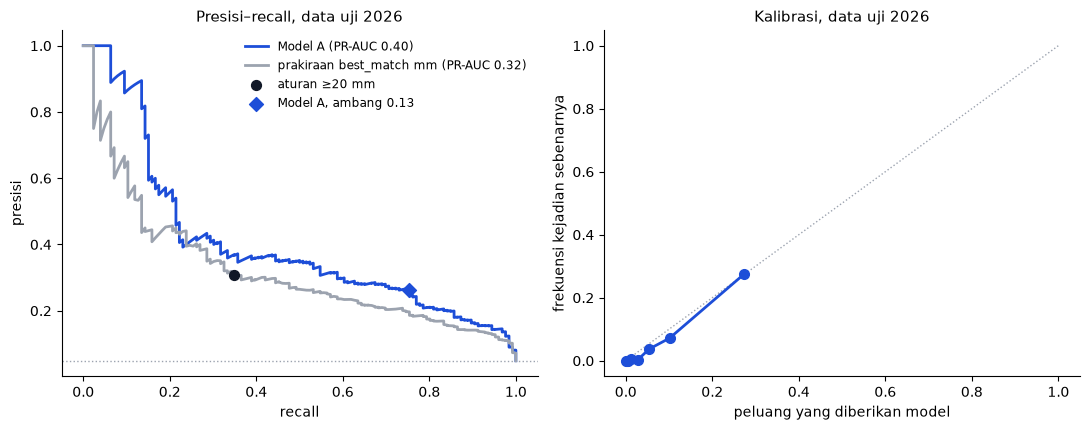

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
pr_p, pr_r, _ = precision_recall_curve(y["test"], p_test)
ax.plot(pr_r, pr_p, color="#1d4ed8", lw=2, label=f"Model A (PR-AUC {champ_test['pr_auc']:.2f})")
bp, br, _ = precision_recall_curve(y["test"], d["test"]["fc_bm_mm"])
ax.plot(br, bp, color="#9ca3af", lw=2, label=f"prakiraan best_match mm (PR-AUC {base['test']['pr_auc']:.2f})")
ax.scatter([base["test"]["recall"]], [base["test"]["precision"]], color="#111827", zorder=3, s=50, label="aturan ≥20 mm")
ax.scatter([champ_test["recall"]], [champ_test["precision"]], color="#1d4ed8", marker="D", zorder=3, s=50, label=f"Model A, ambang {threshold:.2f}")
ax.axhline(y["test"].mean(), color="#9ca3af", ls=":", lw=1)
ax.set_xlabel("recall"); ax.set_ylabel("presisi"); ax.set_title("Presisi–recall, data uji 2026", fontsize=11)
ax.legend(frameon=False, fontsize=8.5); ax.spines[["top", "right"]].set_visible(False)
ax = axes[1]
frac, mean_p = calibration_curve(y["test"], p_test, n_bins=8, strategy="quantile")
ax.plot([0, 1], [0, 1], color="#9ca3af", ls=":", lw=1)
ax.plot(mean_p, frac, marker="o", color="#1d4ed8", lw=2, markersize=7)
ax.set_xlabel("peluang yang diberikan model"); ax.set_ylabel("frekuensi kejadian sebenarnya")
ax.set_title("Kalibrasi, data uji 2026", fontsize=11); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("/tmp/model_a_test_curves.png", dpi=130); plt.show()

### Apakah selisihnya nyata? Bootstrap per tanggal

Data uji hanya punya 126 hari-kota ≥20 mm. Tanggal di-*resample* 2.000 kali. Delapan kota pada tanggal yang sama ikut terambil bersama, karena cuacanya saling berkaitan. Untuk tiap sampel dihitung selisih PR-AUC dan F1 antara Model A dan pembanding.

In [9]:
rng = np.random.default_rng(SEED)
dates = d["test"]["date"].to_numpy()
uniq = np.unique(dates)
rows_by_date = {t: np.flatnonzero(dates == t) for t in uniq}
yt, base_score, base_pred = y["test"], d["test"]["fc_bm_mm"].to_numpy(), ma.baseline_rule(d["test"])
deltas = []
for _ in range(2000):
    idx = np.concatenate([rows_by_date[t] for t in rng.choice(uniq, size=len(uniq), replace=True)])
    if yt[idx].sum() == 0:
        continue
    deltas.append((average_precision_score(yt[idx], p_test[idx]) - average_precision_score(yt[idx], base_score[idx]),
                   f1_score(yt[idx], pred_test[idx]) - f1_score(yt[idx], base_pred[idx])))
deltas = np.array(deltas)
boot = pd.DataFrame({"median": np.median(deltas, axis=0), "IK 95% bawah": np.quantile(deltas, .025, axis=0),
                     "IK 95% atas": np.quantile(deltas, .975, axis=0), "P(Model A lebih baik)": (deltas > 0).mean(axis=0)},
                    index=["selisih PR-AUC", "selisih F1"])
boot

,median,IK 95% bawah,IK 95% atas,P(Model A lebih baik)
selisih PR-AUC,0.078,0.013,0.141,0.992
selisih F1,0.065,-0.004,0.139,0.958


In [10]:
imp = permutation_importance(calibrated, X["test"], y["test"], scoring="average_precision", n_repeats=10, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=ma.FEATURES).sort_values(ascending=False)
importance.head(12).to_frame("penurunan PR-AUC bila diacak")

,penurunan PR-AUC bila diacak
fc_ecmwf_mm,0.200
cloud_mean,0.120
fc_mean_mm,0.080
fc_gfs_mm,0.040
rh_mean,0.035
fc_bm_max_mm_h,0.025
cape_max,0.015
city_semarang,0.009
fc_max_mm,0.008
rain_1d_mm,0.007


## 6. Daftarkan model di MLflow

Model didaftarkan sebagai `siaganusa-hujan` dengan alias `@champion` **hanya kalau** mengalahkan pembanding di data uji, baik PR-AUC maupun F1. API nanti memuat model lewat alias ini.

In [11]:
beats = champ_test["pr_auc"] > base["test"]["pr_auc"] and champ_test["f1"] > base["test"]["f1"]
with mlflow.start_run(run_name=f"champion-{champ_name}") as run:
    mlflow.set_tags({**TAGS, "model": champ_name, "tahap": "juara: kalibrasi sigmoid di validasi, nilai di uji",
                     "mengalahkan_pembanding": str(beats)})
    mlflow.log_params({"threshold": round(threshold, 4), "kalibrasi": "sigmoid (validasi)", "n_fitur": len(ma.FEATURES)})
    mlflow.log_metrics({f"test_{k}": v for k, v in champ_test.items()})
    mlflow.log_metrics({f"baseline_test_{k}": v for k, v in base["test"].items()})
    mlflow.log_metrics({"boot_delta_pr_auc_median": boot.iloc[0, 0], "boot_delta_pr_auc_ci_low": boot.iloc[0, 1],
                        "boot_delta_pr_auc_ci_high": boot.iloc[0, 2], "boot_delta_f1_ci_low": boot.iloc[1, 1],
                        "boot_delta_f1_ci_high": boot.iloc[1, 2]})
    mlflow.log_artifact("/tmp/model_a_test_curves.png")
    importance.to_csv("/tmp/model_a_importance.csv", header=["delta_pr_auc"]); mlflow.log_artifact("/tmp/model_a_importance.csv")
    # MLflow 3 menyimpan model sklearn dengan skops (tanpa pickle); tipe kalibrasi harus diizinkan eksplisit.
    trusted = ["numpy.dtype", "sklearn.calibration._CalibratedClassifier", "sklearn.calibration._SigmoidCalibration"]
    info = mlflow.sklearn.log_model(calibrated, name="model", input_example=X["test"].head(3),
                                    signature=infer_signature(X["test"], p_test), skops_trusted_types=trusted)
if beats:
    mv = mlflow.register_model(info.model_uri, "siaganusa-hujan")
    client = mlflow.MlflowClient()
    client.set_registered_model_alias("siaganusa-hujan", "champion", mv.version)
    client.set_model_version_tag("siaganusa-hujan", mv.version, "threshold", f"{threshold:.4f}")
    print(f"terdaftar: siaganusa-hujan versi {mv.version} @champion")
else:
    print("tidak didaftarkan: tidak mengalahkan pembanding di data uji")

Successfully registered model 'siaganusa-hujan'.
2026/11/23 15:06:33 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: siaganusa-hujan, version 1


🏃 View run champion-logreg-C0.1 at: http://127.0.0.1:5000/#/experiments/4/runs/5d33400242ec44fe9b357081c0369a4f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


terdaftar: siaganusa-hujan versi 1 @champion


Created version '1' of model 'siaganusa-hujan'.


## Kesimpulan

**Model A (regresi logistik, C=0,1, dikalibrasi) mengalahkan pembanding di data uji 2026** dan didaftarkan sebagai `siaganusa-hujan` versi 1 `@champion`.

| Data uji Jan–Nov 2026 (2.568 kota-hari, 126 hari ≥20 mm) | Aturan ≥20 mm | Model A |
|---|:-:|:-:|
| PR-AUC | 0,323 | **0,404** |
| F1 | 0,327 | **0,391** |
| Recall | 0,349 | **0,754** |
| Presisi | **0,308** | 0,264 |
| Recall pada hari ≥50 mm | 2 dari 7 | **5 dari 7** |
| Brier skill terhadap klimatologi | – | 0,235 |

- **Bootstrap per tanggal:** selisih PR-AUC +0,078 dengan IK 95% [+0,013; +0,141]. Model A lebih baik di 99% sampel. Selisih F1 +0,065, IK [−0,004; +0,139].
- **Kalibrasi:** titik-titik di grafik kalibrasi berimpit dengan diagonal. Peluang "27%" memang terjadi sekitar 27% kali, jadi peluangnya bisa ditampilkan apa adanya.
- **Model sederhana menang.** Regresi logistik mengalahkan random forest dan XGBoost di validasi. Dengan data ±2,8 tahun, model pohon cenderung menghafal data latih.
- **Sumber keunggulannya adalah gabungan model cuaca.** Fitur terpenting adalah prakiraan **ECMWF**, tutupan awan, dan rata-rata 4 model. Pembanding hanya memakai best_match, padahal korelasi peringkat ECMWF dengan ERA5 (0,79) lebih tinggi daripada best_match (0,70).

**Keterbatasan:**

1. **Ambang 0,13 mengutamakan recall.** Tiga dari empat hari hujan sedang tertangkap, tetapi hanya seperempat peringatan yang benar-benar terjadi. Di UI yang ditampilkan adalah **peluangnya**, bukan ya/tidak.
2. **Data hanya ±2,8 tahun** karena arsip prakiraan sehari-sebelumnya baru ada sejak Februari 2024. Kalau tidak memakai arsip ini, satu-satunya pilihan adalah Historical Forecast, yang membocorkan jawaban.
3. **Labelnya ERA5.** ERA5 adalah rata-rata area ±25 km, bukan pengukuran stasiun, dan meremehkan hujan ekstrem lokal.
4. **Data uji 2026 lebih kering** (4,9% hari positif dibanding 8,6% di data latih). PR-AUC perlu dibandingkan dengan proporsi itu.

**Rencana:** latih ulang setiap akhir musim hujan dengan data yang bertambah. Model pohon dicoba lagi kalau data sudah ≥4 tahun.